<a href="https://colab.research.google.com/github/darialgt/MN/blob/main/%D0%9B%D0%A04_%D0%9C%D0%B0%D1%82%D1%87%D0%B5%D0%BD%D0%BA%D0%BE_3_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота №4. Регресійні моделі: глибоке дослідження

**Датасет:** Car Price Prediction Multiple Linear Regression  
https://www.kaggle.com/datasets/hellbuoy/car-price-prediction?select=CarPrice_Assignment.csv

**Мета роботи:** виконати підготовку даних, побудувати та порівняти регресійні моделі для прогнозування ціни автомобіля, оцінити їх якість і проаналізувати отримані результати.

> У шаблоні наведено лише умови завдань. Реалізацію необхідно виконати самостійно у порожніх комірках.


## 1. Завантаження та первинний аналіз даних

Завантажити датасет та виконати його первинний огляд:
- визначити кількість об'єктів і ознак;
- переглянути назви стовпців;
- визначити типи даних;
- визначити цільову змінну;
- вивести основні статистичні характеристики даних.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display, Markdown
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, mean_absolute_percentage_error
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, PowerTransformer, StandardScaler
from sklearn.svm import SVR

sns.set_theme(style="whitegrid")
url = "https://raw.githubusercontent.com/ameenmanna8824/DATASETS/main/CarPrice_Assignment.csv"
df = pd.read_csv(url)

print("Розмір:", df.shape)
print("Стовпці:", df.columns.tolist())
print("Цільова змінна: price")
display(df.dtypes.to_frame("Тип"))
display(df.describe(include="all").T)
print("Висновок: датасет містить 205 автомобілів і 26 стовпців.")

Розмір: (205, 26)
Стовпці: ['car_ID', 'symboling', 'CarName', 'fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight', 'enginetype', 'cylindernumber', 'enginesize', 'fuelsystem', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg', 'price']
Цільова змінна: price


,Тип
car_ID,int64
symboling,int64
CarName,object
fueltype,object
aspiration,object
doornumber,object
carbody,object
drivewheel,object
enginelocation,object
wheelbase,float64


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
car_ID,205.0,NaN,NaN,NaN,103.0,59.322565,1.0,52.0,103.0,154.0,205.0
symboling,205.0,NaN,NaN,NaN,0.834146,1.245307,-2.0,0.0,1.0,2.0,3.0
CarName,205,147,peugeot 504,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fueltype,205,2,gas,185,NaN,NaN,NaN,NaN,NaN,NaN,NaN
aspiration,205,2,std,168,NaN,NaN,NaN,NaN,NaN,NaN,NaN
doornumber,205,2,four,115,NaN,NaN,NaN,NaN,NaN,NaN,NaN
carbody,205,5,sedan,96,NaN,NaN,NaN,NaN,NaN,NaN,NaN
drivewheel,205,3,fwd,120,NaN,NaN,NaN,NaN,NaN,NaN,NaN
enginelocation,205,2,front,202,NaN,NaN,NaN,NaN,NaN,NaN,NaN
wheelbase,205.0,NaN,NaN,NaN,98.756585,6.021776,86.6,94.5,97.0,102.4,120.9


Висновок: датасет містить 205 автомобілів і 26 стовпців.


## 2. Перевірка якості даних

Перевірити:
- наявність пропущених значень;
- наявність повних дублікатів;
- кількість унікальних значень в ознаках.

Під час аналізу врахувати, що `car_ID` є унікальним ідентифікатором автомобіля і сам по собі не повинен використовуватися для визначення дублікатів за змістовими характеристиками.


In [2]:
print("Пропуски:", df.isna().sum().sum())
print("Повні дублікати:", df.duplicated().sum())
print("Дублікати без car_ID:", df.drop(columns="car_ID").duplicated().sum())
display(df.nunique().to_frame("Унікальних значень"))
print("Висновок: пропусків і дублікатів немає; car_ID є унікальним.")

Пропуски: 0
Повні дублікати: 0
Дублікати без car_ID: 0


,Унікальних значень
car_ID,205
symboling,6
CarName,147
fueltype,2
aspiration,2
doornumber,2
carbody,5
drivewheel,3
enginelocation,2
wheelbase,53


Висновок: пропусків і дублікатів немає; car_ID є унікальним.


## 3. Робота з car_ID

Зберегти `car_ID` окремо для подальшої ідентифікації автомобілів у результатах прогнозування.  
Не використовувати `car_ID` як ознаку під час навчання моделей.


In [3]:
car_ids = df["car_ID"].copy()

# Із повної назви залишаємо марку, щоб уникнути майже унікальних категорій.
df["brand"] = df["CarName"].str.split().str[0].str.lower().replace({
    "maxda": "mazda", "porcshce": "porsche", "toyouta": "toyota",
    "vokswagen": "volkswagen", "vw": "volkswagen"
})
df = df.drop(columns=["car_ID", "CarName"])

print("Збережені car_ID:", car_ids.head().tolist())
print("Висновок: car_ID збережено окремо і не використовується як предиктор.")

Збережені car_ID: [1, 2, 3, 4, 5]
Висновок: car_ID збережено окремо і не використовується як предиктор.


## 4. Дослідження розподілів числових ознак

Дослідити розподіли числових ознак:
- побудувати відповідні графіки;
- обчислити коефіцієнти асиметрії;
- визначити ознаки з найбільш вираженою асиметрією;
- коротко прокоментувати отримані результати.


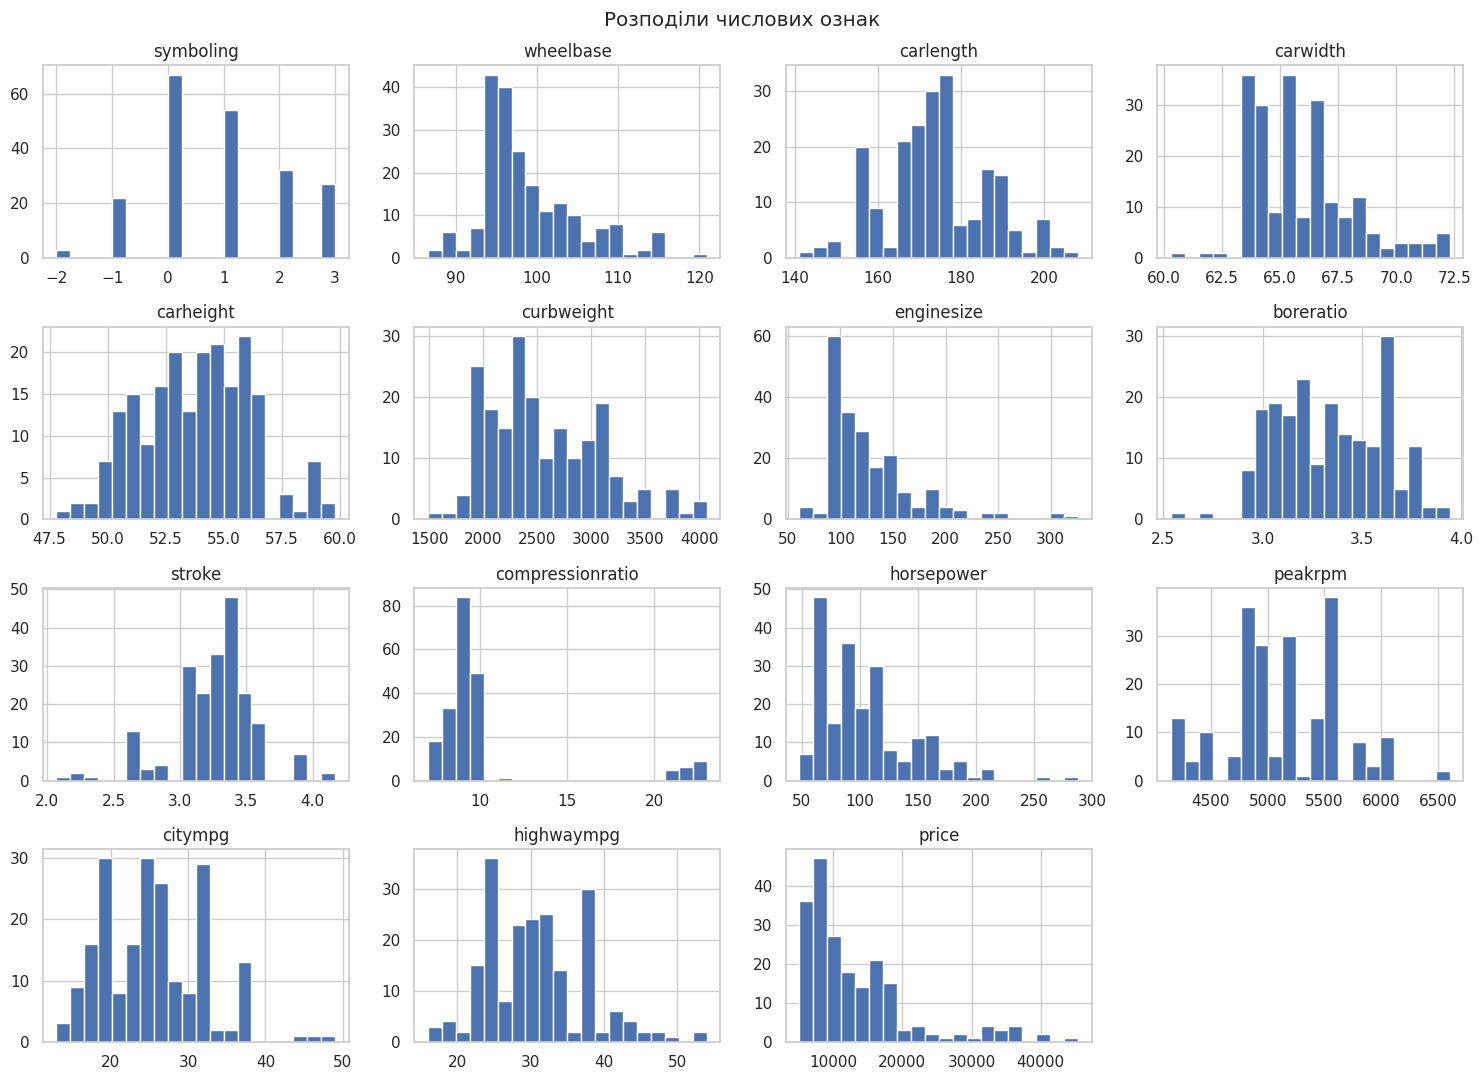

,Асиметрія
compressionratio,2.610862
enginesize,1.947655
price,1.777678
horsepower,1.405310
wheelbase,1.050214
carwidth,0.904003
stroke,-0.689705
curbweight,0.681398
citympg,0.663704
highwaympg,0.539997


Найбільш асиметричні: ['compressionratio', 'enginesize', 'price', 'horsepower', 'wheelbase']
Висновок: для зменшення асиметрії далі використовується Yeo–Johnson.


In [4]:
numeric = df.select_dtypes(include=np.number)
numeric.hist(bins=20, figsize=(15, 11))
plt.suptitle("Розподіли числових ознак")
plt.tight_layout()
plt.show()

skew_before = numeric.skew().sort_values(key=abs, ascending=False)
display(skew_before.to_frame("Асиметрія"))
print("Найбільш асиметричні:", skew_before[abs(skew_before) > 1].index.tolist())
print("Висновок: для зменшення асиметрії далі використовується Yeo–Johnson.")

## 5. Формування train/test вибірок

Відокремити цільову змінну `price` від ознак та розділити дані на:
- навчальну вибірку — 80%;
- тестову вибірку — 20%.

Забезпечити відтворюваність поділу.  
Окремо зберегти `car_ID` для об'єктів, які потрапили до train і test.

**Важливо:** усі подальші параметри передобробки даних визначати тільки за навчальною вибіркою.


In [5]:
X = df.drop(columns="price")
y = df["price"]

X_train, X_test, y_train, y_test, id_train, id_test = train_test_split(
    X, y, car_ids, test_size=0.2, random_state=42
)

print("Train:", X_train.shape, "Test:", X_test.shape)
print("Висновок: дані поділено 80/20; random_state=42 забезпечує відтворюваність.")

Train: (164, 24) Test: (41, 24)
Висновок: дані поділено 80/20; random_state=42 забезпечує відтворюваність.


## 6. Аналіз та обробка викидів

Для неперервних числових ознак навчальної вибірки:
- визначити потенційні викиди методом IQR;
- вивести кількість потенційних викидів для кожної ознаки;
- обґрунтувати спосіб їх обробки.

Для невеликого набору даних не видаляти автоматично всі рядки з викидами. Використати обмеження крайніх значень межами, визначеними за навчальною вибіркою.

Цільову змінну `price` не використовувати для визначення меж викидів.  
До тестової вибірки застосувати ті самі межі, які були отримані за train.


In [6]:
continuous = [c for c in X_train.select_dtypes(include=np.number) if c != "symboling"]
bounds = {}
outliers = {}

for c in continuous:
    q1, q3 = X_train[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    bounds[c] = (q1 - 1.5 * iqr, q3 + 1.5 * iqr)
    outliers[c] = ((X_train[c] < bounds[c][0]) | (X_train[c] > bounds[c][1])).sum()

display(pd.Series(outliers, name="Кількість викидів").sort_values(ascending=False).to_frame())

for c, (low, high) in bounds.items():
    X_train[c] = X_train[c].clip(low, high)
    X_test[c] = X_test[c].clip(low, high)

print("Висновок: рядки не видалено; значення обмежено IQR-межами з train.")

,Кількість викидів
compressionratio,20
stroke,16
carwidth,10
horsepower,7
enginesize,7
wheelbase,6
peakrpm,2
highwaympg,1
boreratio,1
curbweight,0


Висновок: рядки не видалено; значення обмежено IQR-межами з train.


## 7. Аналіз кореляцій та відбір ознак

За навчальною вибіркою:
- побудувати матрицю кореляцій числових ознак;
- знайти пари ознак із сильною кореляцією, для яких `|r| > 0.85`;
- для кожної такої пари залишити одну ознаку;
- під час вибору врахувати силу зв'язку кожної ознаки з цільовою змінною `price`;
- вивести список сильно корельованих пар та перелік ознак, які видаляються.

Із тестової вибірки видалити ті самі ознаки.  
Не використовувати тестову вибірку для прийняття рішення про відбір ознак.


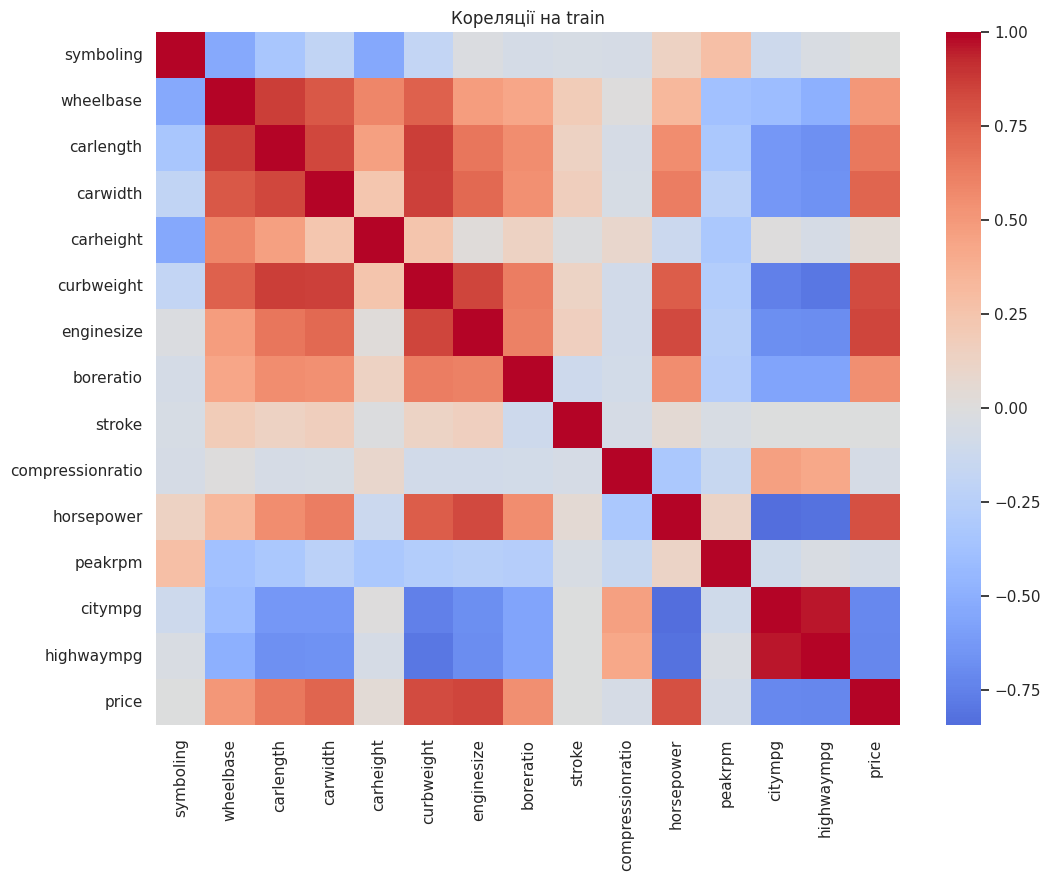

,Ознака 1,Ознака 2,r
0,wheelbase,carlength,0.867043
1,carlength,curbweight,0.865988
2,carwidth,curbweight,0.858047
3,citympg,highwaympg,0.963620


Видалено: ['carlength', 'carwidth', 'citympg', 'wheelbase']
Висновок: із сильно корельованих пар видалено ознаки зі слабшим зв'язком із price.


In [7]:
corr_data = X_train.select_dtypes(include=np.number).copy()
corr_data["price"] = y_train
corr = corr_data.corr()

plt.figure(figsize=(12, 9))
sns.heatmap(corr, cmap="coolwarm", center=0)
plt.title("Кореляції на train")
plt.show()

pairs = []
cols = X_train.select_dtypes(include=np.number).columns
for i, a in enumerate(cols):
    for b in cols[i + 1:]:
        if abs(corr.loc[a, b]) > 0.85:
            pairs.append([a, b, corr.loc[a, b]])

pairs_df = pd.DataFrame(pairs, columns=["Ознака 1", "Ознака 2", "r"])
display(pairs_df)

drop_cols = set()
for a, b, r in pairs:
    if a not in drop_cols and b not in drop_cols:
        drop_cols.add(a if abs(corr.loc[a, "price"]) < abs(corr.loc[b, "price"]) else b)

drop_cols = sorted(drop_cols)
X_train = X_train.drop(columns=drop_cols)
X_test = X_test.drop(columns=drop_cols)
print("Видалено:", drop_cols)
print("Висновок: із сильно корельованих пар видалено ознаки зі слабшим зв'язком із price.")

## 8. Підготовка числових і категоріальних ознак

Розділити ознаки на:
- неперервні числові;
- дискретну числову ознаку `symboling`;
- категоріальні.

Для неперервних числових ознак виконати послідовно:
1. перетворення Yeo–Johnson для зменшення асиметрії;
2. масштабування за допомогою StandardScaler.

Для `symboling` виконати масштабування без Yeo–Johnson.

Категоріальні ознаки закодувати методом One-Hot Encoding. Передбачити коректну обробку категорій у test, яких не було у train.

Усі перетворення об'єднати в єдиний механізм передобробки даних, який навчається тільки на `X_train`.


In [8]:
num_cols = X_train.select_dtypes(include=np.number).columns.tolist()
continuous = [c for c in num_cols if c != "symboling"]
symboling = ["symboling"] if "symboling" in X_train else []
categorical = X_train.select_dtypes(exclude=np.number).columns.tolist()

preprocessor = ColumnTransformer([
    ("continuous", Pipeline([
        ("power", PowerTransformer(method="yeo-johnson")),
        ("scale", StandardScaler())
    ]), continuous),
    ("symboling", StandardScaler(), symboling),
    ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical)
])

print("Неперервні:", continuous)
print("Дискретна:", symboling)
print("Категоріальні:", categorical)
print("Висновок: створено єдиний механізм передобробки ознак.")

Неперервні: ['carheight', 'curbweight', 'enginesize', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'highwaympg']
Дискретна: ['symboling']
Категоріальні: ['fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'enginetype', 'cylindernumber', 'fuelsystem', 'brand']
Висновок: створено єдиний механізм передобробки ознак.


## 9. Перевірка трансформації числових ознак

Перевірити результат трансформації неперервних числових ознак:
- застосувати до train ту саму послідовність перетворень, яка буде використана в моделях;
- повторно обчислити коефіцієнти асиметрії;
- порівняти їх із початковими значеннями;
- зробити короткий висновок щодо ефективності трансформації.


In [9]:
power = PowerTransformer(method="yeo-johnson")
transformed = pd.DataFrame(power.fit_transform(X_train[continuous]), columns=continuous)

skew_comparison = pd.DataFrame({
    "До": X_train[continuous].skew(),
    "Після": transformed.skew().values
})
display(skew_comparison)
print("Середнє |skew| до:", round(skew_comparison["До"].abs().mean(), 3))
print("Середнє |skew| після:", round(skew_comparison["Після"].abs().mean(), 3))
print("Висновок: Yeo–Johnson зменшив загальну асиметрію числових ознак.")

,До,Після
carheight,0.028154,-0.005170
curbweight,0.712433,0.049894
enginesize,0.962394,0.044834
boreratio,0.062963,-0.005941
stroke,-0.397600,0.015846
compressionratio,0.055710,0.004872
horsepower,0.850735,0.066280
peakrpm,0.039773,-0.003589
highwaympg,0.243761,-0.012188


Середнє |skew| до: 0.373
Середнє |skew| після: 0.023
Висновок: Yeo–Johnson зменшив загальну асиметрію числових ознак.


## 10. Побудова регресійних моделей

Побудувати та навчити такі моделі:
- Linear Regression;
- Ridge Regression;
- Lasso Regression;
- Random Forest Regressor;
- Gradient Boosting Regressor;
- Support Vector Regressor (SVR).

Для кожної моделі створити єдиний Pipeline, який містить:
1. попередню обробку ознак;
2. відповідну регресійну модель.

Використати однакову схему підготовки даних для коректного порівняння моделей.


In [10]:
models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=10),
    "Lasso": Lasso(alpha=10, max_iter=50000),
    "Random Forest": RandomForestRegressor(n_estimators=300, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=300, learning_rate=0.03, max_depth=2, random_state=42),
    "SVR": TransformedTargetRegressor(
        regressor=SVR(C=100, epsilon=0.05), transformer=StandardScaler()
    )
}

pipelines = {
    name: Pipeline([("preprocessing", preprocessor), ("model", model)])
    for name, model in models.items()
}

print("Створено моделей:", len(pipelines))
print("Висновок: кожна модель об'єднана з передобробкою у Pipeline.")

Створено моделей: 6
Висновок: кожна модель об'єднана з передобробкою у Pipeline.


## 11. Оцінювання якості моделей

Для кожної моделі:
- виконати навчання на тренувальній вибірці;
- отримати прогноз для тестової вибірки;
- обчислити метрики **R², MAE, MSE та MAPE**.

`MAPE` подати у відсотках.

Результати всіх моделей об'єднати в одну порівняльну таблицю та впорядкувати за значенням R² від найбільшого до найменшого.

Під час інтерпретації врахувати:
- R² — чим більше, тим краще;
- MAE, MSE, MAPE — чим менше, тим краще.


In [11]:
results = []
predictions = {}

for name, model in pipelines.items():
    model.fit(X_train, y_train)
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)
    predictions[name] = test_pred
    results.append([
        name,
        r2_score(y_train, train_pred),
        r2_score(y_test, test_pred),
        mean_absolute_error(y_test, test_pred),
        mean_squared_error(y_test, test_pred),
        mean_absolute_percentage_error(y_test, test_pred) * 100
    ])

results = pd.DataFrame(results, columns=["Модель", "Train R²", "Test R²", "MAE", "MSE", "MAPE, %"])
results = results.sort_values("Test R²", ascending=False).reset_index(drop=True)
display(results.round(3))
print("Висновок: найкраща модель —", results.loc[0, "Модель"])


,Модель,Train R²,Test R²,MAE,MSE,"MAPE, %"
0,Random Forest,0.985,0.955,1311.091,3.519785e+06,9.642
1,SVR,0.993,0.937,1572.004,4.953184e+06,13.981
2,Gradient Boosting,0.980,0.929,1751.039,5.579342e+06,12.992
3,Linear Regression,0.960,0.879,2156.098,9.518236e+06,16.376
4,Lasso,0.953,0.850,2350.373,1.180724e+07,17.376
5,Ridge,0.882,0.783,2918.453,1.711034e+07,25.496


Висновок: найкраща модель — Random Forest


## 12. Пояснення вибору типу моделі

Пояснити, чому класифікаційна модель, наприклад Logistic Regression, не підходить для безпосереднього прогнозування неперервної ціни автомобіля.

Зазначити, до якого типу задачі належить прогнозування `price` та чому моделі, використані в роботі, відповідають цій задачі.


Прогнозування price — це задача регресії, бо ціна є неперервним числом. Logistic Regression призначена для класифікації, тому для прямого прогнозування ціни вона не підходить. Усі використані в роботі моделі є регресійними.

## 13. Візуальне порівняння прогнозів

Для кожної побудованої моделі зобразити співвідношення:
- фактичних значень `price`;
- прогнозованих значень `price`.

Додати лінію ідеального прогнозу та проаналізувати, наскільки близько до неї розташовані прогнозовані значення. Звернути увагу на великі відхилення.


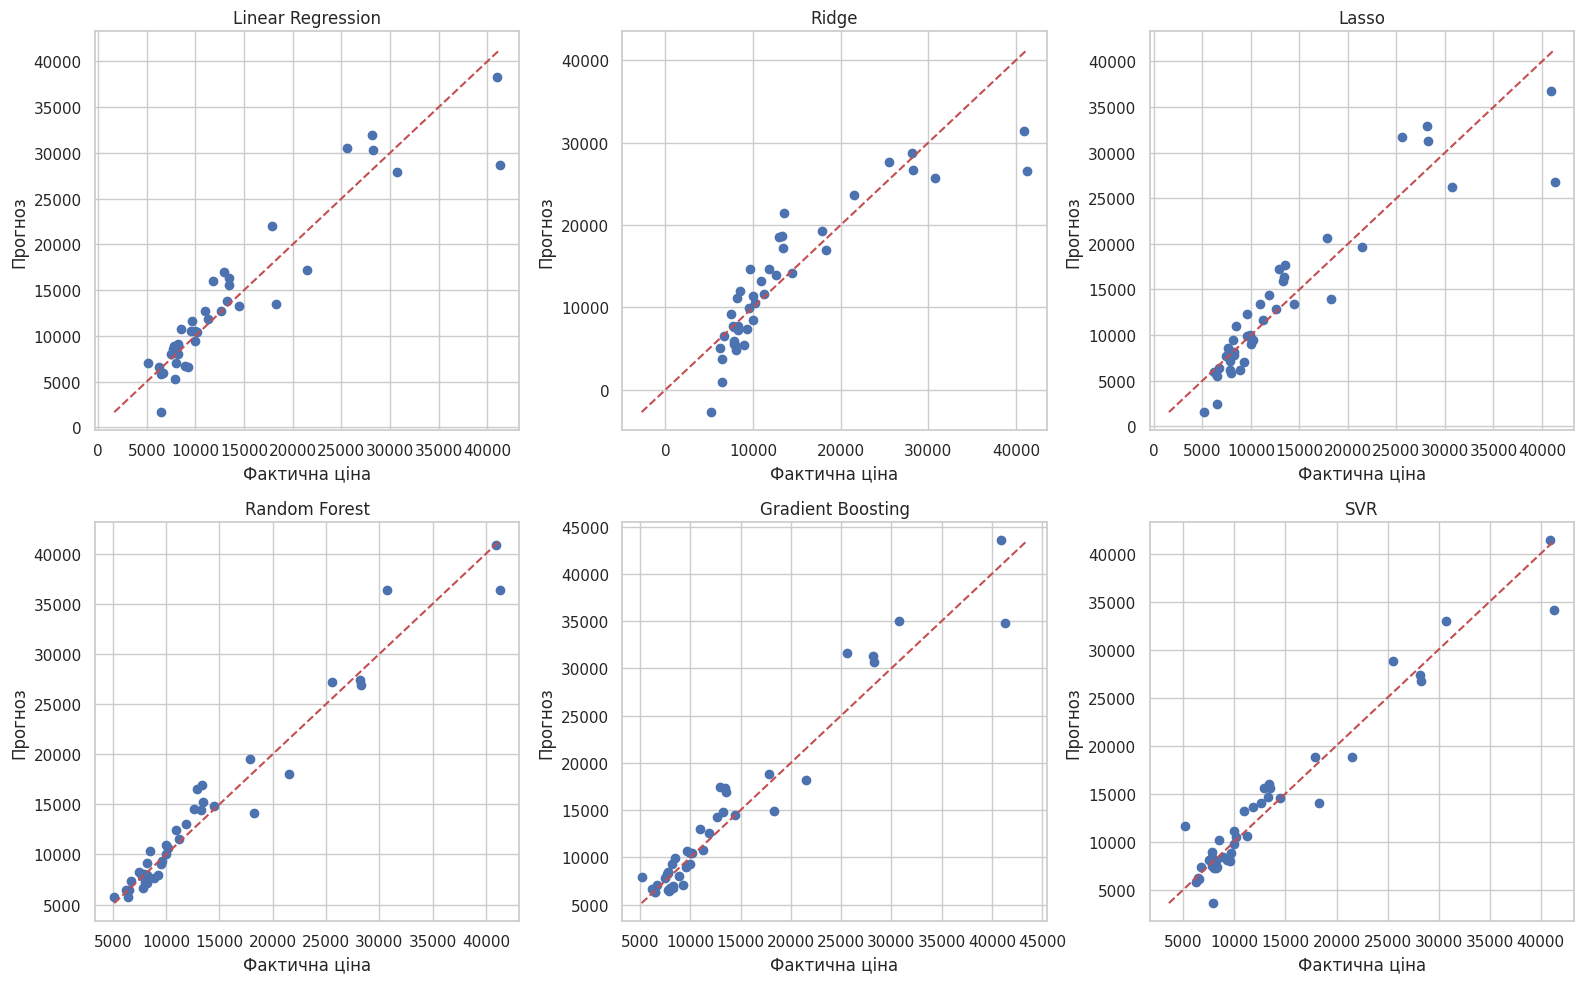

Висновок: кращим моделям відповідають точки, розташовані ближче до червоної лінії.


In [12]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

for ax, (name, pred) in zip(axes.ravel(), predictions.items()):
    low = min(y_test.min(), pred.min())
    high = max(y_test.max(), pred.max())
    ax.scatter(y_test, pred)
    ax.plot([low, high], [low, high], "r--")
    ax.set_title(name)
    ax.set_xlabel("Фактична ціна")
    ax.set_ylabel("Прогноз")

plt.tight_layout()
plt.show()
print("Висновок: кращим моделям відповідають точки, розташовані ближче до червоної лінії.")

## 14. Прогноз для 10 автомобілів

Випадково вибрати 10 автомобілів із тестової вибірки.

За допомогою моделі Random Forest отримати для них прогноз ціни та сформувати таблицю з такими даними:
- `car_ID`;
- фактична ціна;
- прогнозована ціна;
- абсолютна помилка;
- абсолютна відсоткова помилка.

Прокоментувати отримані результати.


In [13]:
sample = X_test.sample(10, random_state=42).index
rf_pred = pd.Series(predictions["Random Forest"], index=X_test.index)

table = pd.DataFrame({
    "car_ID": id_test.loc[sample].astype(int),
    "Фактична ціна": y_test.loc[sample],
    "Прогнозована ціна": rf_pred.loc[sample]
})
table["Абсолютна помилка"] = abs(table["Фактична ціна"] - table["Прогнозована ціна"])
table["Абсолютна відсоткова помилка, %"] = table["Абсолютна помилка"] / table["Фактична ціна"] * 100

display(table.round(2))
print("Середня похибка, %:", round(table["Абсолютна відсоткова помилка, %"].mean(), 2))
print("Висновок: car_ID дає змогу зіставити прогноз із конкретним автомобілем.")

,car_ID,Фактична ціна,Прогнозована ціна,Абсолютна помилка,"Абсолютна відсоткова помилка, %"
25,26,6692.0,7322.24,630.24,9.42
175,176,9988.0,10929.02,941.02,9.42
147,148,10198.0,10695.45,497.45,4.88
16,17,41315.0,36368.71,4946.29,11.97
68,69,28248.0,26909.69,1338.31,4.74
146,147,7463.0,8294.29,831.29,11.14
143,144,9960.0,10062.71,102.71,1.03
84,85,14489.0,14825.76,336.76,2.32
194,195,12940.0,16563.30,3623.30,28.00
159,160,7788.0,7827.16,39.16,0.50


Середня похибка, %: 8.34
Висновок: car_ID дає змогу зіставити прогноз із конкретним автомобілем.


## 15. Висновки

Сформулювати підсумкові висновки за результатами роботи.

У висновках:
- порівняти якість усіх моделей;
- проаналізувати R², MAE, MSE і MAPE;
- зазначити, яка модель показала найкращі результати за отриманими метриками;
- прокоментувати величину похибок;
- звернути увагу на можливі ознаки перенавчання;
- коротко оцінити вплив попередньої обробки даних на результати моделювання.


Найкращою моделлю стала Random Forest: Test R² = 0.955, MAE = 1311.09, MSE = 3519785.42, MAPE = 9.64%.
Найбільший розрив між Train R² і Test R² має Lasso, що може свідчити про перенавчання. Уся передобробка виконувалась за train-вибіркою. Обмеження викидів, Yeo–Johnson, масштабування, кодування категорій і відбір корельованих ознак дали змогу коректно підготувати дані та порівняти моделі.

## Загальні вимоги до виконання

- Не використовувати тестову вибірку для визначення меж викидів, кореляційного відбору ознак, навчання трансформерів, масштабування або кодування категорій.
- Усі параметри передобробки мають визначатися тільки за навчальною вибіркою.
- Фінальні метрики моделей обчислювати на тестовій вибірці.
- Не використовувати `car_ID` як предиктор.
- Не видаляти спостереження або ознаки без пояснення причини.
- До кожного основного етапу додати короткий змістовний висновок.
- У підсумкових висновках спиратися на отримані метрики та графіки.
